# 02 - Preprocessing: Penanganan Nilai Hilang

Notebook sebelumnya (`01_EDA`) menemukan bahwa lima atribut
fisiologis -- `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`,
`BMI` -- memiliki nilai 0 yang secara medis merepresentasikan data
hilang, bukan pengukuran sebenarnya. Notebook ini menangani nilai
tersebut melalui dua tahap: menandainya sebagai `NaN`, lalu
mengimputasinya dengan median per kelas `Outcome`. Seluruh logika
pembersihan diimplementasikan pada `src/preprocessing.py` sehingga
dapat dipakai ulang oleh `main.py` maupun notebook lain, dan dites
langsung di sini terhadap data sebenarnya.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_data
from src.preprocessing import (
    ZERO_AS_MISSING_COLUMNS,
    mark_missing,
    count_missing,
    impute_missing_by_class,
)

DATA_PATH = PROJECT_ROOT / "data" / "diabetes.csv"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

df = load_data(DATA_PATH)
print(f"Data mentah dimuat: {df.shape}")


Data mentah dimuat: (768, 9)


## 1. Tandai Nilai 0 sebagai Data Hilang

`mark_missing` mengganti nilai 0 pada kelima kolom fisiologis menjadi
`NaN`, tanpa mengubah kolom lain (`Pregnancies` = 0 dan
`DiabetesPedigreeFunction` mendekati 0 valid secara medis, sehingga
tidak termasuk `ZERO_AS_MISSING_COLUMNS`).


In [2]:
df_ditandai = mark_missing(df)
jumlah_hilang = count_missing(df_ditandai)

print("Kolom yang diperlakukan sebagai data hilang jika bernilai 0:")
print(" ", ZERO_AS_MISSING_COLUMNS)
print()
for kolom, jumlah in jumlah_hilang.items():
    print(f"  {kolom:15s}: {jumlah:3d} nilai hilang ({jumlah/len(df)*100:.1f}%)")


Kolom yang diperlakukan sebagai data hilang jika bernilai 0:
  ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

  Glucose        :   0 nilai hilang (0.0%)
  BloodPressure  :   0 nilai hilang (0.0%)
  SkinThickness  :   0 nilai hilang (0.0%)
  Insulin        :   0 nilai hilang (0.0%)
  BMI            :   0 nilai hilang (0.0%)


## 2. Imputasi Median per Kelas

Median dipakai (bukan rata-rata) karena lebih tahan terhadap outlier,
dan dihitung **terpisah per kelas** `Outcome` karena rentang nilai
fisiologis normal berbeda antara pasien diabetes dan bukan diabetes --
median `Glucose` pada kelompok `Outcome=1` secara medis wajar lebih
tinggi daripada kelompok `Outcome=0`. Menggunakan median gabungan akan
mengaburkan perbedaan ini.

> **Catatan metodologis (dibahas juga di `04_Evaluation`):** imputasi
> ini dijalankan sebelum data dibagi menjadi data latih/uji, mengikuti
> urutan tahap yang ditetapkan pada spesifikasi tugas. Konsekuensinya,
> median yang dipakai untuk baris yang nanti menjadi data uji turut
> dihitung memakai label `Outcome` baris itu sendiri -- kebocoran data
> berskala kecil pada tahap praproses, bukan kebocoran label langsung
> ke prediksi. Pengaruhnya kecil karena imputasi hanya menggeser
> sebagian nilai fitur menuju median kelasnya.


In [3]:
df_bersih = impute_missing_by_class(df_ditandai)

print("Jumlah NaN tersisa setelah imputasi:", int(df_bersih[ZERO_AS_MISSING_COLUMNS].isna().sum().sum()))
df_bersih[ZERO_AS_MISSING_COLUMNS].describe().T[["mean", "std", "min", "max"]]


Jumlah NaN tersisa setelah imputasi: 0


,mean,std,min,max
Glucose,121.677083,30.464161,44.0,199.0
BloodPressure,72.389323,12.106039,24.0,122.0
SkinThickness,29.089844,8.890820,7.0,99.0
Insulin,141.753906,89.100847,14.0,846.0
BMI,32.434635,6.880498,18.2,67.1


## 3. Sebelum vs Sesudah Imputasi


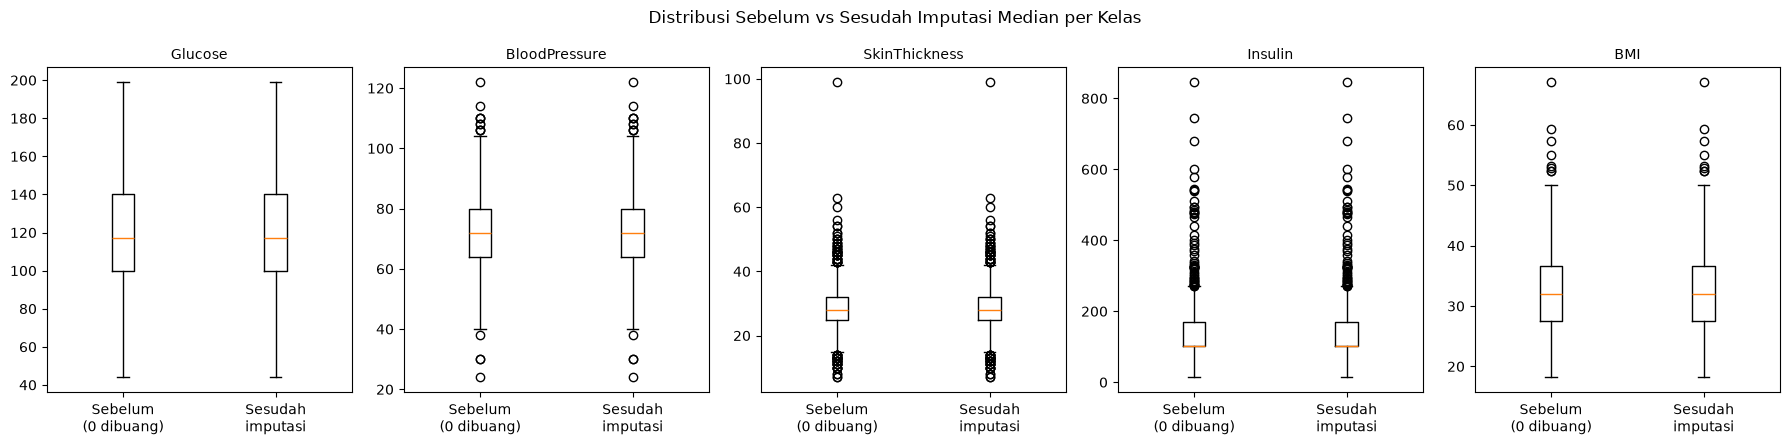

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4.5))
for ax, kolom in zip(axes, ZERO_AS_MISSING_COLUMNS):
    data_sebelum = df_ditandai[kolom].dropna()
    data_sesudah = df_bersih[kolom]
    ax.boxplot([data_sebelum, data_sesudah], tick_labels=["Sebelum\n(0 dibuang)", "Sesudah\nimputasi"])
    ax.set_title(kolom, fontsize=10)
fig.suptitle("Distribusi Sebelum vs Sesudah Imputasi Median per Kelas")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "preprocessing_before_after.png", dpi=150)
plt.show()


Bentuk distribusi secara umum tetap terjaga (median dipilih justru
agar tidak mendistorsi tendensi sentral), dengan perbedaan paling
kentara pada `Insulin` dan `SkinThickness` -- dua kolom dengan
proporsi nilai hilang terbesar (48,7% dan 29,6%).


## 4. Simpan Dataset Bersih

Dataset hasil pembersihan disimpan ke `data/processed/diabetes_clean.csv`
agar `03_GaussianNB` dapat memuatnya langsung tanpa mengulang tahap
ini -- inilah yang membuat pembagian antar notebook benar-benar
modular: setiap notebook menghasilkan artefak nyata yang dipakai
notebook berikutnya, bukan hanya salinan kode yang dijalankan ulang.


In [5]:
output_path = PROCESSED_DIR / "diabetes_clean.csv"
df_bersih.to_csv(output_path, index=False)
print(f"Tersimpan: {output_path} ({df_bersih.shape[0]} baris, {df_bersih.shape[1]} kolom)")


Tersimpan: d:\diabetes-risk-gnb\data\processed\diabetes_clean.csv (768 baris, 9 kolom)


## 5. Median Data Latih untuk Kebutuhan Deployment (Aplikasi Streamlit)

Median per kelas di atas cocok untuk perbandingan model pada
`03_GaussianNB` dan `04_Evaluation` karena mengikuti urutan tahap pada
spesifikasi tugas. Namun median tersebut **tidak bisa dipakai
langsung oleh aplikasi deteksi langsung (Streamlit)**, karena saat
seorang pasien baru diperiksa, label `Outcome` sebenarnya justru
belum diketahui -- itulah yang sedang diprediksi.

Untuk kebutuhan deployment, bagian ini menghitung median dari seluruh
data mentah (tanpa bergantung pada label kelas) sebagai nilai
pengganti ketika pengguna aplikasi tidak mengetahui salah satu
indikator. Ini secara sengaja dipisahkan dari alur akademik di atas
agar kedua kebutuhan -- reproduksi hasil sesuai spesifikasi tugas, dan
kebenaran metodologis saat model benar-benar dipakai pada data baru
tanpa label -- sama-sama terpenuhi tanpa saling mencampuri.


In [6]:
import json

median_keseluruhan = df_ditandai[ZERO_AS_MISSING_COLUMNS].median()
MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(exist_ok=True)

with open(MODELS_DIR / "imputation_medians.json", "w", encoding="utf-8") as f:
    json.dump({k: round(float(v), 2) for k, v in median_keseluruhan.items()}, f, indent=2, ensure_ascii=False)

median_keseluruhan


Glucose          117.00
BloodPressure     72.00
SkinThickness     28.00
Insulin          102.50
BMI               32.05
dtype: float64

**Lanjut ke `03_GaussianNB.ipynb`** untuk pelatihan model Gaussian
Naive Bayes menggunakan dataset bersih ini.
